# Statistics of FORGE Dataset

In [ ]:
import os
import json
from dataclasses import dataclass
from dataclasses import field
from typing import List, Dict, Union, Optional, Literal
from pydantic import BaseModel, RootModel, Field
from collections import namedtuple,Counter

@dataclass
class ProjectInfo:
    url: Union[str, int, List, None] = "n/a"
    commit_id: Union[str, int, List, None] = "n/a"
    address: Union[str, int, List, None] = "n/a"
    chain: Union[str, int, List, None] = "n/a"
    compiler_version: Union[str, List, None] = "n/a"
    audit_date: Union[str, int, List, None] = "n/a"
    project_path: Union[str, List, Dict, None] = "n/a"

    def is_empty(self):
        if (self.url == "n/a" and self.address == "n/a") or (
            not self.url and not self.address
        ):
            return True
        return False

@dataclass
class Finding:
    id: Union[str, int] = 0
    category: Dict = field(default_factory=dict)
    title: str = ""
    description: str = ""
    severity: Optional[str] = ""
    location: Union[str, int, List] = ""


class Report(BaseModel):
    path: str = ""
    project_info: ProjectInfo = field(default_factory=ProjectInfo)
    findings: List[Finding] = field(default_factory=list)

    def append_finding(self, finding: Finding):
        self.findings.append(finding)


class JSONFileProcessor:
    def __init__(self, directory: str):
        self.directory = directory
        self.file_count = 0

    def _get_all_json_files(self) -> List[str]:
        json_files = []
        for root, _, files in os.walk(self.directory):
            for file in files:
                if file.endswith(".json"):
                    json_files.append(os.path.join(root, file))
                    self.file_count += 1
        return json_files

    def operate_add(self,results:List,result_type):
        res = {}
        for field in result_type._fields:
            if isinstance(getattr(results[0],field),int):
                res[field] = 0
            else:
                res[field] = []
            # res[field] = 0
        for result in results:
            for field in result._fields:
                res[field] += getattr(result, field)

        return res
    def operate_reduce(self,results:List,result_type):
        res = {}
        for field in result_type._fields:
            res[field] = []
        for result in results:
            for field in result._fields:
                res[field].extend(getattr(result, field))
        return res

    def process_files(
        self, analysis_func=None, modify_func=None
    ) -> List[Report]:
        results = []
        json_files = self._get_all_json_files()
        for json_file in json_files:
            # print(f"Processing file: {json_file}")
            with open(json_file, "r", encoding="utf8") as f:
                data = json.load(f)
            report = Report(**data)
            if analysis_func:
                result = analysis_func(report)
                results.append(result)
            if modify_func:
                modified_report: Report = modify_func(report)
                with open(json_file, "w", encoding="utf8") as f:
                    f.write(modified_report.model_dump_json(indent=4,exclude={'project_info': {'compiler_version'}}))
        return results

class CWE(BaseModel):
    ID: int
    Name: str
    Description: str = ""
    Abstraction: Literal["Pillar", "Class", "Base", "Variant", "Compound"]
    Mapping: Literal["Allowed", "Allowed-with-Review", "Discouraged", "Prohibited"]
    Peer: List = Field(default_factory=list)
    Parent: List = Field(default_factory=list)
    Child: List[int] = Field(default_factory=list)

    def __str__(self) -> str:
        return f"CWE-{self.ID}: {self.Name}"

    def __hash__(self):
        return hash(str(self))

    def add_child(self, child_cwe: "CWE"):
        self.Child.append(child_cwe)
        child_cwe.Parent.append(self)


class CWEDatabase(RootModel):
    root: Dict[str, CWE]

    def get_by_id(self, id: int | str):
        name = f"CWE-{id}"
        return self.root[name]

    def get_by_name(self, name: str):
        return self.root[name]

severity_score_map = {
    "info": (0, 0, 0),
    "low": (0.1, 3.9, 2),
    "medium": (4.0, 6.9, 5.45),
    "high": (7.0, 8.9, 7.95),
    "critical": (9.0, 10.0, 9.5),
}

class CWEHandler:
    def __init__(self, cwe_database: CWEDatabase):
        self.db = cwe_database
        self.setup_relationships()

    @classmethod
    def load_from_file(cls, file_path: str) -> "CWEHandler":
        import json

        with open(file_path, "r") as f:
            data = json.load(f)
        # CWEDatabase expects a dict where keys are CWE IDs (strings) and values are CWE objects
        db = CWEDatabase.model_validate(data)
        return cls(db)

    def setup_relationships(self):
        """
        Build the parent-child relationships (DAG) based on the 'Child' field (List[int]).
        Populates the 'Parent' field (List[CWE]) for each CWE.
        """
        # First pass: Convert any integer IDs in Parent to CWE objects or clear if invalid
        for cwe in self.db.root.values():
            cleaned_parents = []
            for p in cwe.Parent:
                if isinstance(p, CWE):
                    cleaned_parents.append(p)
                elif isinstance(p, int):
                    try:
                        parent_cwe = self.db.get_by_id(p)
                        cleaned_parents.append(parent_cwe)
                    except KeyError:
                        pass
            cwe.Parent = cleaned_parents

        # Second pass: Build relationships from Child fields
        for cwe_key, cwe in self.db.root.items():
            for child_id in cwe.Child:
                try:
                    child_cwe = self.db.get_by_id(child_id)
                    # Add current cwe as parent to the child
                    # Check if already exists to avoid duplicates if run multiple times
                    if cwe not in child_cwe.Parent:
                        child_cwe.Parent.append(cwe)
                except KeyError:
                    # Child ID might not exist in the database
                    continue

    def get_cwe(self, cwe_id: Union[int, str]) -> Optional[CWE]:
        try:
            if isinstance(cwe_id, int):
                return self.db.get_by_id(cwe_id)
            elif isinstance(cwe_id, str):
                if cwe_id.startswith("CWE-"):
                    return self.db.root[cwe_id]
                else:
                    return self.db.get_by_id(int(cwe_id))
        except (KeyError, ValueError):
            return None

    def get_direct_children(self, cwe_id: Union[int, str]) -> List[CWE]:
        cwe = self.get_cwe(cwe_id)
        if not cwe:
            return []
        children = []
        for child_id in cwe.Child:
            child = self.get_cwe(child_id)
            if child:
                children.append(child)
        return children

    def get_direct_parents(self, cwe_id: Union[int, str]) -> List[CWE]:
        cwe = self.get_cwe(cwe_id)
        if not cwe:
            return []
        return cwe.Parent

    def get_all_descendants(self, cwe_id: Union[int, str]) -> List[CWE]:
        cwe = self.get_cwe(cwe_id)
        if not cwe:
            return []
        descendants = set()
        queue = [cwe]
        while queue:
            current = queue.pop(0)
            for child_id in current.Child:
                child = self.get_cwe(child_id)
                if child and child not in descendants:
                    descendants.add(child)
                    queue.append(child)
        return list(descendants)

    def get_root_parents(self, cwe_id: Union[int, str]) -> List[CWE]:
        """
        Recursively find the most root parents (Pillars).
        """
        cwe = self.get_cwe(cwe_id)
        if not cwe:
            return []

        roots = set()
        queue = [cwe]
        visited = set()

        while queue:
            current = queue.pop(0)
            if current in visited:
                continue
            visited.add(current)

            # If it's a Pillar, it's a root
            if current.Abstraction == "Pillar":
                roots.add(current)
                continue  # Stop traversing up from a Pillar? Usually yes.

            # If no parents, it's a root
            if not current.Parent:
                roots.add(current)
                continue

            # Otherwise, traverse up
            for parent in current.Parent:
                queue.append(parent)

        return list(roots)

    def is_related(self, id1: Union[int, str], id2: Union[int, str]) -> bool:
        """
        Check if there is any inheritance relationship between two CWEs.
        Returns True if id1 is ancestor of id2 OR id2 is ancestor of id1.
        """
        cwe1 = self.get_cwe(id1)
        cwe2 = self.get_cwe(id2)

        if not cwe1 or not cwe2:
            return False

        if cwe1 == cwe2:
            return True

        # Check if cwe1 is ancestor of cwe2
        if self._is_ancestor(cwe1, cwe2):
            return True

        # Check if cwe2 is ancestor of cwe1
        if self._is_ancestor(cwe2, cwe1):
            return True

        return False

    def _is_ancestor(self, ancestor: CWE, descendant: CWE) -> bool:
        # BFS up from descendant to find ancestor
        queue = [descendant]
        visited = set()
        while queue:
            current = queue.pop(0)
            if current in visited:
                continue
            visited.add(current)

            if current == ancestor:
                return True

            for parent in current.Parent:
                queue.append(parent)
        return False


## Clone FORGE Dataset

In [ ]:
import subprocess
import os
from pathlib import Path

# Configuration
REPO_URL = "https://github.com/shenyimings/FORGE-Artifacts"
TARGET_DIR = Path("FORGE-Artifacts")

def clone_forge_dataset():
    """Clone FORGE EVM repository if not already exists"""
    if TARGET_DIR.exists():
        print(f"✓ Repository already exists at: {TARGET_DIR.resolve()}")
        print(f"To clone, run: git -C {TARGET_DIR} pull")
        return True
    
    print(f"Cloning repository from {REPO_URL}...")
    print(f"Target directory: {TARGET_DIR.resolve()}")
    
    try:
        # Create parent directory if needed
        TARGET_DIR.parent.mkdir(parents=True, exist_ok=True)
        
        # Clone the repository
        result = subprocess.run(
            ["git", "clone", REPO_URL, str(TARGET_DIR)],
            capture_output=True,
            text=True,
            check=True
        )
        
        print(f"✓ Successfully cloned to: {TARGET_DIR.resolve()}")
        return True
        
    except subprocess.CalledProcessError as e:
        print(f"✗ Error cloning repository:")
        print(f"  {e.stderr}")
        return False
    except Exception as e:
        print(f"✗ Unexpected error: {e}")
        return False


clone_forge_dataset()

## Count findings & projects

In [ ]:
Finding = namedtuple("Finding", ["total_files","total_projects","total_findings"])

def count_finding(report: Report):
    if isinstance(report.project_info.url,list):
        # print(report.path)
        project_count = len(report.project_info.url)
    else:
        project_count = 1
    result = Finding(total_findings=len(report.findings),total_files=1,total_projects=project_count)
    return result

processor = JSONFileProcessor("FORGE-Artifacts/dataset/results")
results = processor.process_files(analysis_func=count_finding)
res = processor.operate_add(results,Finding)
res

{'total_files': 6454, 'total_projects': 6454, 'total_findings': 27495}

## Severity statistics

In [ ]:
severity_category = ["na","info","low","medium","high","critical"]

Severity = namedtuple("Category",severity_category)
def count_severity(report: Report):
    findings = report.findings
    severity_dict = {"na": 0, "info": 0, "low": 0, "medium": 0, "high": 0, "critical": 0}
    for finding in findings:
        severity = finding.severity
        if severity:
            severity = finding.severity.lower().strip()
        
        if severity == None or severity == "" or severity == "n/a":
            severity = "na"
        
        
        if severity not in severity_category:
            continue
        severity_dict[severity] = severity_dict.get(severity, 0) + 1
        # dict to namedtuple
    return Severity(**severity_dict)

processor = JSONFileProcessor("FORGE-Artifacts/dataset/results")
results = processor.process_files(analysis_func=count_severity)
res = processor.operate_add(results, Severity)
res

{'na': 2406,
 'info': 3456,
 'low': 15170,
 'medium': 3367,
 'high': 2094,
 'critical': 1004}

## CWE-Id statistics

In [ ]:
CWE_tuple = namedtuple("CWE", ["cwe_ids"])

# Load CWE Handler for DAG traversal
try:
    cwe_handler = CWEHandler.load_from_file("../rq5/auditor/cwe_dict.json")
except Exception as e:
    print(f"Warning: Could not load CWE database: {e}")
    cwe_handler = None

def extract_last_cwe_ids(report: Report):
    cwe_ids = []
    for finding in report.findings:
        if finding.category:
            # Get the ID with the highest key from the category dictionary
            try:
                max_key = max([int(k) for k in finding.category.keys() if k.isdigit()])
                cwe_value = finding.category.get(str(max_key), [""])[0]
                # Extract CWE ID if it exists
                if isinstance(cwe_value, str) and cwe_value.startswith("CWE-"):
                    cwe_ids.append(cwe_value)
            except (ValueError, AttributeError):
                continue
    return CWE_tuple(cwe_ids=[cwe_id for cwe_id in cwe_ids])

def extract_pillar_cwe_ids(report: Report):
    cwe_ids = []
    for finding in report.findings:
        if finding.category:
            try:
                max_key = max([int(k) for k in finding.category.keys() if k.isdigit()])
                cwe_value = finding.category.get(str(max_key), [""])[0]
                
                if isinstance(cwe_value, str) and cwe_value.startswith("CWE-"):
                    if cwe_handler:
                        # Use CWEHandler to find all Pillar ancestors (DAG support)
                        # e.g., CWE-346 may have multiple Pillar ancestors like CWE-284 and CWE-693
                        pillars = cwe_handler.get_root_parents(cwe_value)
                        
                        # Add each pillar found
                        # if len(pillars)>1:
                            # print(f"Finding multiple pillars for {cwe_value} in report {report.path}: {[pillar.ID for pillar in pillars]}")
                        for pillar in pillars:
                            cwe_ids.append(f"CWE-{pillar.ID}")
                    else:
                        # Fallback for when handler isn't available: use pre-calculated level 1
                        cwe_value = finding.category.get("1", [""])[0]
                        if isinstance(cwe_value, str) and cwe_value.startswith("CWE-"):
                            cwe_ids.append(cwe_value)
            except (ValueError, AttributeError):
                continue
    return CWE_tuple(cwe_ids=[cwe_id for cwe_id in cwe_ids])

# processor = JSONFileProcessor("../../dataset/findings")
processor = JSONFileProcessor("FORGE-Artifacts/dataset/results")

results = processor.process_files(analysis_func=extract_last_cwe_ids)
results_pillar = processor.process_files(analysis_func=extract_pillar_cwe_ids)
# results_pillar_evm = processor_evm.process_files(analysis_func=extract_pillar_cwe_ids)

cwe_pillar_result = processor.operate_reduce(results_pillar, CWE_tuple)
# cwe_pillar_result_evm = processor_evm.operate_reduce(results_pillar_evm, CWE)
cwe_result = processor.operate_reduce(results, CWE_tuple)

# Count unique CWE IDs
unique_cwe_ids = set(cwe_result["cwe_ids"])
cwe_counter = Counter(cwe_result["cwe_ids"])

print(f"Total unique CWE IDs: {len(unique_cwe_ids)}")


print("Top 10 CWE IDs by occurrence:")
for cwe_id, count in cwe_counter.most_common(10):
    print(f"{cwe_id}: {count}")

print(f"Total unique Pillar CWE IDs: {len(set(cwe_pillar_result['cwe_ids']))}")
print("Top 10 Pillar CWE IDs by occurrence:")
# cwe_pillar_counter_evm = Counter(cwe_pillar_result_evm["cwe_ids"])
cwe_pillar_counter = Counter(cwe_pillar_result["cwe_ids"])
for cwe_id, count in cwe_pillar_counter.most_common(10):
    print(f"{cwe_id}: {count}")


print(cwe_pillar_counter.most_common(10))
# print(cwe_pillar_counter_evm.most_common(10))

Total unique CWE IDs: 296
Top 10 CWE IDs by occurrence:
CWE-710: 3099
CWE-1041: 2640
CWE-682: 2514
CWE-269: 2025
CWE-754: 1930
CWE-284: 1711
CWE-1068: 801
CWE-755: 674
CWE-266: 575
CWE-20: 555
Total unique Pillar CWE IDs: 10
Top 10 Pillar CWE IDs by occurrence:
CWE-710: 9555
CWE-284: 6197
CWE-703: 3676
CWE-682: 3201
CWE-664: 2471
CWE-691: 1353
CWE-693: 772
CWE-707: 670
CWE-435: 636
CWE-697: 365
[('CWE-710', 9555), ('CWE-284', 6197), ('CWE-703', 3676), ('CWE-682', 3201), ('CWE-664', 2471), ('CWE-691', 1353), ('CWE-693', 772), ('CWE-707', 670), ('CWE-435', 636), ('CWE-697', 365)]


In [ ]:
import sys
from collections import Counter, namedtuple

# sys.path.append("../../../src")
# from core.models import CWE, CWEDatabase

# Load CWE Handler for DAG traversal and proper Parent-Child linking
try:
    cwe_handler = CWEHandler.load_from_file("../rq5/auditor/cwe_dict.json")
    cwe_database = cwe_handler.db # Reference to the underlying database
except Exception as e:
    print(f"Error loading CWE database: {e}")
    # Fallback to manual loading if handler fails (though unlikely if previous cells worked)
    cwe_path = "../rq5/auditor/cwe_dict.json"
    with open(cwe_path, "r", encoding="utf8") as f:
        cwe_database = CWEDatabase.model_validate_json(f.read())
    cwe_handler = None 


result = namedtuple("CWE", ["cwe_name", "severity_score"])
no_severity_count = {}

def count_cwe(report: Report):
    """Extract CWE IDs and severity scores from findings"""
    findings = report.findings
    cwe_names = []
    severity_score = []
    
    for finding in findings:
        if not finding.category:
            continue

        # Get the CWE from the deepest categorization level
        final_key = max(finding.category.keys())
        cwe_name_list = finding.category.get(final_key, None)
        
        try:
            cwe_list = []
            if cwe_name_list:
                for name in cwe_name_list:
                    # Resolve name to ID
                    try:
                        obj = cwe_database.get_by_name(name)
                        cwe_list.append(obj.ID)
                    except KeyError:
                        pass
            
            cwe_list = cwe_list[0:1]  # Take only the first CWE
        except Exception as e:
            print(f"Error finding {finding.id} in {report.path}: {e}")
            continue
            
        if cwe_list:
            cwe_names.extend(cwe_list)
            
        # Handle severity scoring
        if not finding.severity or finding.severity.lower().strip() == "n/a":
            no_severity_count[cwe_list[0]] = no_severity_count.get(cwe_list[0], 0) + 1
        else:
            # Look up severity score
            s_map = severity_score_map.get(finding.severity.lower().strip(), (0, 0, 0))
            severity_score.append((
                cwe_list[0],
                s_map[2], # Use the score value
            ))
            
    return result(cwe_name=cwe_names, severity_score=severity_score)

# Process all finding files

processor = JSONFileProcessor("FORGE-Artifact/dataset/results")
results = processor.process_files(analysis_func=count_cwe)
res = processor.operate_reduce(results, result)

# ---------------- Prepare Basic Statistics ----------------

# Aggregate severity info for weighted average calculation later
cwe_raw_stats = {} # cwe_id -> {'sum_score': float, 'count_rated': int}

for cwe_id, score in res["severity_score"]:
    if cwe_id not in cwe_raw_stats:
        cwe_raw_stats[cwe_id] = {'sum_score': 0.0, 'count_rated': 0}
    cwe_raw_stats[cwe_id]['sum_score'] += score
    cwe_raw_stats[cwe_id]['count_rated'] += 1

# Calculate average severity scores for each CWE (Individual)
cwe_count = Counter(res["cwe_name"])
cwe_severity = {}

for cwe_id, stats in cwe_raw_stats.items():
    if stats['count_rated'] > 0:
        cwe_severity[cwe_id] = stats['sum_score'] / stats['count_rated']
    else:
        cwe_severity[cwe_id] = 0

# Sort by frequency
cwe_count = dict(sorted(cwe_count.items(), key=lambda x: x[1], reverse=True))
cwe_count_backup = cwe_count.copy()
cwe_severity_backup = cwe_severity.copy()



# =============================================================================
# TOP SEVERITY ANALYSIS (DAG Aware)
# =============================================================================

print("\nTop 10 CWEs by Average Severity Score:")
original_severity_sorted = sorted(cwe_severity.items(), key=lambda x: x[1], reverse=True)

severity_rank = 0
for cwe_id, severity_score in original_severity_sorted:
    if severity_rank >= 10:
        break
    if cwe_count[cwe_id] > 15:  # Only show CWEs with significant occurrence
        cwe_info = cwe_database.get_by_id(cwe_id)
        print(f"CWE-{cwe_id}: {cwe_info.Name}, {cwe_count[cwe_id]}, {severity_score:.3f}")
        severity_rank += 1


print("\nTop 10 Pillar CWEs by Average Severity Score (DAG-aware):")

pillars = [284, 435, 664, 682, 691, 693, 697, 703, 707, 710]
pillar_hierarchical_stats = []

for pillar_id in pillars:
    if not cwe_handler:
        continue
        
    # 1. Get ALL descendants in the DAG (Unique Set)
    # This handles diamonds (multiple paths to same child) correctly by returning a Set
    descendants = cwe_handler.get_all_descendants(pillar_id)
    
    # 2. Include the pillar itself
    pillar_cwe = cwe_handler.get_cwe(pillar_id)
    relevant_cwes = [pillar_cwe] + descendants if pillar_cwe else descendants
    
    # 3. Aggregate Stats
    total_occurrence = 0
    total_weighted_severity_sum = 0
    total_rated_findings = 0
    cwes_with_severity = 0
    
    for cwe in relevant_cwes:
        cwe_id = cwe.ID
        
        # Count total findings
        count = cwe_count.get(cwe_id, 0)
        total_occurrence += count
        
        # Accumulate severity (Weighted Average strategy)
        # We sum up the raw scores of all underlying findings
        if cwe_id in cwe_raw_stats:
            stats = cwe_raw_stats[cwe_id]
            total_weighted_severity_sum += stats['sum_score']
            total_rated_findings += stats['count_rated']
            if stats['count_rated'] > 0:
                cwes_with_severity += 1
                
    # Calculate Pillar Average
    if total_rated_findings > 0:
        avg_severity = total_weighted_severity_sum / total_rated_findings
    else:
        avg_severity = 0
        
    pillar_hierarchical_stats.append((pillar_id, avg_severity, total_occurrence))

# Sort and Print
pillar_hierarchical_stats.sort(key=lambda x: x[1], reverse=True)

for pillar_id, avg_severity, total_count in pillar_hierarchical_stats:
    if avg_severity > 0:
        cwe_info = cwe_database.get_by_id(pillar_id)
        print(f"CWE-{pillar_id}: {cwe_info.Name}, {total_count} occurrences, {avg_severity:.3f} avg severity")

print(cwe_severity[346])


Top 10 CWEs by Average Severity Score:
CWE-940: Improper Verification of Source of a Communication Channel, 22, 6.150
CWE-369: Divide By Zero, 53, 5.558
CWE-1265: Unintended Reentrant Invocation of Non-reentrant Code Via Nested Calls, 281, 5.143
CWE-347: Improper Verification of Cryptographic Signature, 29, 4.909
CWE-287: Improper Authentication, 25, 4.884
CWE-269: Improper Privilege Management, 2025, 4.810
CWE-362: Concurrent Execution using Shared Resource with Improper Synchronization ('Race Condition'), 97, 4.770
CWE-863: Incorrect Authorization, 264, 4.745
CWE-282: Improper Ownership Management, 231, 4.729
CWE-284: Improper Access Control, 1711, 4.715

Top 10 Pillar CWEs by Average Severity Score (DAG-aware):
CWE-284: Improper Access Control, 6197 occurrences, 4.583 avg severity
CWE-435: Improper Interaction Between Multiple Correctly-Behaving Entities, 636 occurrences, 3.518 avg severity
CWE-691: Insufficient Control Flow Management, 1353 occurrences, 3.461 avg severity
CWE-693:

## Solana v.s EVM: Severity & Frequency Comparison

In [9]:
import plotly.graph_objects as go
import pandas as pd


solana_data = [
    ('CWE-697', 34, 3.960),
    ('CWE-284', 161, 4.337),
    ('CWE-691', 149, 3.731),
    ('CWE-682', 260, 4.324),
    ('CWE-693', 157, 4.442),
    ('CWE-664', 270, 3.720),
    ('CWE-435', 52, 3.153),
    ('CWE-707', 248, 2.961),
    ('CWE-703', 118, 2.957),
    ('CWE-710', 301, 1.340)
]

evm_data = [
    ('CWE-693', 772, 3.392),
    ('CWE-664', 2471, 3.337),
    ('CWE-284', 6197, 4.583),
    ('CWE-707', 670, 2.974),
    ('CWE-691', 1353, 3.461),
    ('CWE-682', 3201, 3.383),
    ('CWE-703', 3676, 2.516),
    ('CWE-435', 636, 3.518),
    ('CWE-697', 365, 2.718),
    ('CWE-710', 9555, 1.873)
]
average_score_solana = sum([item[2] for item in solana_data]) / len(solana_data)
average_score_evm = sum([item[2] for item in evm_data]) / len(evm_data)
print(f"Average Severity Score - Solana: {average_score_solana:.3f}")
print(f"Average Severity Score - EVM: {average_score_evm:.3f}")

Average Severity Score - Solana: 3.492
Average Severity Score - EVM: 3.176


/var/folders/t_/b4p6m_s51fj9ss8wlvrrmf9c0000gn/T/ipykernel_15900/3056753159.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{abs(tick):.1f}' for tick in ticks])


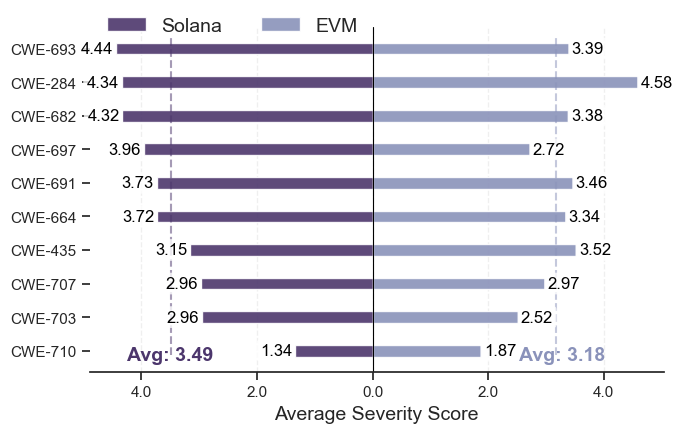

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# solana_data = [('CWE-664', 269), ('CWE-682', 260), ('CWE-707', 250), ('CWE-710', 301), ('CWE-693', 156), ('CWE-691', 149), ('CWE-703', 118), ('CWE-284', 161), ('CWE-435', 53), ('CWE-697', 34)]
# evm_data = [('CWE-710', 9555), ('CWE-284', 6197), ('CWE-703', 3676), ('CWE-682', 3201), ('CWE-664', 2471), ('CWE-691', 1353), ('CWE-435', 636), ('CWE-693', 772), ('CWE-697', 365), ('CWE-707', 670)]


df_solana = pd.DataFrame(solana_data, columns=['CWE', 'Count', 'Avg_Severity'])
df_evm = pd.DataFrame(evm_data, columns=['CWE', 'Count', 'Avg_Severity'])

all_cwes = sorted(list(set(df_solana['CWE']) | set(df_evm['CWE'])))
df_combined = pd.DataFrame({'CWE': all_cwes})
df_combined = pd.merge(df_combined, df_solana[['CWE', 'Avg_Severity']], on='CWE', how='left').rename(columns={'Avg_Severity': 'Solana_Severity'})
df_combined = pd.merge(df_combined, df_evm[['CWE', 'Avg_Severity']], on='CWE', how='left').rename(columns={'Avg_Severity': 'EVM_Severity'})
df_combined = df_combined.fillna(0)
df_combined = df_combined.sort_values('Solana_Severity', ascending=True)


sns.set_theme(style="ticks")
colors = sns.color_palette("icefire")
solana_color = "#4c366c"
evm_color = '#8a92ba'
fig, ax = plt.subplots(figsize=(7, 4.5))

step=1
y = np.arange(len(df_combined))*step
bar_height = 0.35 

rects1 = ax.barh(y, -df_combined['Solana_Severity'], height=bar_height, label='Solana', color=solana_color, alpha=0.9)
rects2 = ax.barh(y, df_combined['EVM_Severity'], height=bar_height, label='EVM', color=evm_color, alpha=0.9)

# Average lines
ax.axvline(x=-average_score_solana, color=solana_color, linestyle='--', linewidth=1.5, alpha=0.5, ymin=0.05, ymax=0.97)
ax.axvline(x=average_score_evm, color=evm_color, linestyle='--', linewidth=1.5, alpha=0.5, ymin=0.05, ymax=0.97)

# Add text for averages
ax.text(-average_score_solana, 0.15, f'Avg: {average_score_solana:.2f}', color=solana_color, ha='center', va='top', fontsize=14, fontweight='bold')
ax.text(average_score_evm+0.1, 0.15, f'Avg: {average_score_evm:.2f}', color=evm_color, ha='center', va='top', fontsize=14, fontweight='bold')
bbox_props = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8)
# Add value annotations next to bars
for i, (idx, row) in enumerate(df_combined.iterrows()):
    # Solana label (left)
    if row['Solana_Severity'] > 0:
        ax.text(-row['Solana_Severity'] - 0.05, y[i], f"{row['Solana_Severity']:.2f}",va='center', ha='right', fontsize=12, color='black',bbox=bbox_props)
        
    # EVM label (right)
    if row['EVM_Severity'] > 0:
        ax.text(row['EVM_Severity'] + 0.05, y[i], f"{row['EVM_Severity']:.2f}", 
                va='center', ha='left', fontsize=12, color='black',bbox=bbox_props)

# Customizing axes
ax.set_yticks(y)
ax.set_yticklabels(df_combined['CWE'], ha='right')
ax.set_xlabel('Average Severity Score', fontsize=14)
# ax.set_title('Severity Comparison: Solana vs EVM', fontsize=14, pad=20)

# Format x-axis labels to be positive on both sides
ticks = ax.get_xticks()
ax.set_xticklabels([f'{abs(tick):.1f}' for tick in ticks])

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False) 
ax.axvline(0, color='black', linewidth=0.8)

ax.legend(loc='upper left', bbox_to_anchor=(0, 1.08), ncol=2, frameon=False, fontsize=14)

plt.tight_layout()
plt.show()


fig.savefig("rq3_severity.pdf", bbox_inches='tight',pad_inches=0)


## Frequency Comparison Plotting

       CWE  Count  Avg_Severity  Percentage
0  CWE-697     34         3.960    1.942857
1  CWE-284    161         4.337    9.200000
2  CWE-691    149         3.731    8.514286
3  CWE-682    260         4.324   14.857143
4  CWE-693    157         4.442    8.971429
5  CWE-664    270         3.720   15.428571
6  CWE-435     52         3.153    2.971429
7  CWE-707    248         2.961   14.171429
8  CWE-703    118         2.957    6.742857
9  CWE-710    301         1.340   17.200000
       CWE  Count  Avg_Severity  Percentage
0  CWE-693    772         3.392    2.671650
1  CWE-664   2471         3.337    8.551357
2  CWE-284   6197         4.583   21.445875
3  CWE-707    670         2.974    2.318660
4  CWE-691   1353         3.461    4.682309
5  CWE-682   3201         3.383   11.077658
6  CWE-703   3676         2.516   12.721484
7  CWE-435    636         3.518    2.200997
8  CWE-697    365         2.718    1.263151
9  CWE-710   9555         1.873   33.066860


/var/folders/t_/b4p6m_s51fj9ss8wlvrrmf9c0000gn/T/ipykernel_15900/3978908977.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{abs(tick):.0f}' for tick in ticks])


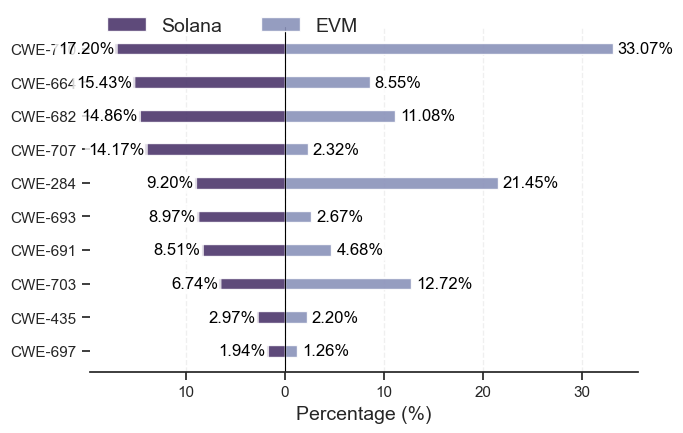

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

total_solana = sum(item[1] for item in solana_data)
total_evm = sum(item[1] for item in evm_data)


df_solana = pd.DataFrame(solana_data, columns=['CWE', 'Count', 'Avg_Severity'])
df_evm = pd.DataFrame(evm_data, columns=['CWE', 'Count', 'Avg_Severity'])


df_solana['Percentage'] = (df_solana['Count'] / total_solana) * 100
df_evm['Percentage'] = (df_evm['Count'] / total_evm) * 100
print(df_solana)
print(df_evm)

all_cwes = sorted(list(set(df_solana['CWE']) | set(df_evm['CWE'])))
df_combined = pd.DataFrame({'CWE': all_cwes})
df_combined = pd.merge(df_combined, df_solana[['CWE', 'Percentage']], on='CWE', how='left').rename(columns={'Percentage': 'Solana_Percentage'})
df_combined = pd.merge(df_combined, df_evm[['CWE', 'Percentage']], on='CWE', how='left').rename(columns={'Percentage': 'EVM_Percentage'})
df_combined = df_combined.fillna(0)
df_combined = df_combined.sort_values('Solana_Percentage', ascending=True)

sns.set_theme(style="ticks")
colors = sns.color_palette("icefire")
solana_color = "#4c366c" 
evm_color = '#8a92ba'

fig, ax = plt.subplots(figsize=(7, 4.5))

step = 1
y = np.arange(len(df_combined)) * step
bar_height = 0.35  # Thin bars

rects1 = ax.barh(y, -df_combined['Solana_Percentage'], height=bar_height, label='Solana', color=solana_color, alpha=0.9)
rects2 = ax.barh(y, df_combined['EVM_Percentage'], height=bar_height, label='EVM', color=evm_color, alpha=0.9)

bbox_props = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8)
# Add value annotations next to bars
for i, (idx, row) in enumerate(df_combined.iterrows()):
    # Solana label (left)
    if row['Solana_Percentage'] > 0:
        ax.text(-row['Solana_Percentage'] -0, y[i], f"{row['Solana_Percentage']:.2f}%", va='center', ha='right', fontsize=12, color='black', bbox=bbox_props)
        
    # EVM label (right)
    if row['EVM_Percentage'] > 0:
        ax.text(row['EVM_Percentage'] + 0.5, y[i], f"{row['EVM_Percentage']:.2f}%", va='center', ha='left', fontsize=12, color='black', bbox=bbox_props)

# Customizing axes
ax.set_yticks(y)
ax.set_yticklabels(df_combined['CWE'], ha='right')
ax.set_xlabel('Percentage (%)', fontsize=14)

# Format x-axis labels to be positive on both sides
ticks = ax.get_xticks()
ax.set_xticklabels([f'{abs(tick):.0f}' for tick in ticks])

# Add grid
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False) # Remove left spine
# Add a center line
ax.axvline(0, color='black', linewidth=0.8)

ax.legend(loc='upper left', bbox_to_anchor=(0, 1.08), ncol=2, frameon=False, fontsize=14)
plt.tight_layout()
plt.show()

fig.savefig("rq3_frequency.pdf", bbox_inches='tight', pad_inches=0)

## Analyze CWE-697

In [ ]:
from pathlib import Path
all_reports = Path("FORGE-Artifact/dataset/results").glob("*.json")
severities = []

for report_path in all_reports:
    try:
        report = Report.model_validate_json(report_path.read_text(encoding="utf8"))
        for finding in report.findings:
            if finding.category:
                final_key = max(finding.category.keys())
                cwe_name_list = finding.category.get(final_key, None)
                if cwe_name_list:
                    for name in cwe_name_list:
                        try:
                            obj = cwe_database.get_by_name(name)
                            roots = cwe_handler.get_root_parents(obj.ID)  # Ensure DAG relationships are used
                            if 697 in [pillar.ID for pillar in roots]:
                                severities.append(finding.severity)
                        except KeyError:
                            pass
    except Exception as e:
        print(f"Error processing {report_path}: {e}")

all_count =len(severities)
print(f"Total findings related to CWE-697 Pillar: {all_count}")
severity_counter = Counter(severities)
print("Severity distribution for CWE-697 related findings:")
for severity, count in severity_counter.items():
    percentage = (count / all_count) * 100
    print(f"{severity}: {count} ({percentage:.2f}%)")

tautology_checks = 67 # number of low-severity tautology_checks categorized as 'CWE-697'
unnecessary_boolean_checks = 86 # number of low-severity unnecessary Boolean checks categorized as 'CWE-697'
all_low_checks = tautology_checks + unnecessary_boolean_checks
print(all_low_checks/all_count)
severity_counter["low"] -= all_low_checks
all_count -= all_low_checks
sev_socre_697 = 0.0
for severity, count in severity_counter.items():
    if severity =='n/a':
        continue
    score = severity_score_map.get(severity, (0, 0, 0))[2]
    sev_socre_697 += score * count
average_sev_score_697 = sev_socre_697 / (all_count - severity_counter.get('n/a',0))
average_sev_score_697



Total findings related to CWE-697 Pillar: 365
Severity distribution for CWE-697 related findings:
low: 220 (60.27%)
n/a: 31 (8.49%)
medium: 41 (11.23%)
high: 20 (5.48%)
info: 44 (12.05%)
critical: 9 (2.47%)
0.4191780821917808


3.3256906077348067